<a href="https://colab.research.google.com/github/ykitaguchi77/chatGPT/blob/main/Pymupdf4LLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Pymupdf4LLM**

https://github.com/pymupdf/pymupdf4llm

In [1]:
!pip install -q pymupdf pymupdf4llm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.1/24.1 MB 82.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.6/66.6 kB 4.9 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ==============================
# 1. 対象PDFのパス（指定ファイル）
# ==============================
pdf_path = "/content/drive/MyDrive/Paperpile/All Papers/A/Abalo-Lojo et al. 2023 - Improvement of Prostaglandin-Associated Periorbitopathy after Discontinuing Treatment.pdf"


# ==============================
# 2. PDFの存在確認
# ==============================
import os

if not os.path.exists(pdf_path):
    raise FileNotFoundError("PDFが見つかりません: " + pdf_path)

print("✅ PDF認識完了")


# ==============================
# 3. 通常テキスト抽出（1ページ目確認）
# ==============================
import fitz  # PyMuPDF

doc = fitz.open(pdf_path)
print("ページ数:", doc.page_count)

page0_text = doc[0].get_text()
print("----- 1ページ目冒頭 -----")
print(page0_text[:1500])


# ==============================
# 4. PymuPDF4LLMでMarkdown化（構造保持）
# ==============================
import pymupdf4llm

md_text = pymupdf4llm.to_markdown(pdf_path)

print("----- LLM向けMarkdown冒頭 -----")
print(md_text[:2000])


# ==============================
# 5. JSONチャンク化（RAG・GPT投入用）
# ==============================
import json

docs = pymupdf4llm.to_markdown(pdf_path, as_dict=True)

print("✅ チャンク数:", len(docs))
print("----- 先頭チャンク -----")
print(json.dumps(docs[0], ensure_ascii=False, indent=2))


# ==============================
# 6. GPT投入用に全チャンクを結合
# ==============================
combined_text = "\n\n".join(
    f"[Page {d.get('page', '?')}] {d.get('text', '')}"
    for d in docs
)

print("----- GPT投入用テキスト冒頭 -----")
print(combined_text[:3000])


# ==============================
# 7. JSONとして保存 & ダウンロード
# ==============================
out_json = "abalo_lojo_2023_pymupdf4llm.json"

with open(out_json, "w", encoding="utf-8") as f:
    json.dump(docs, f, ensure_ascii=False, indent=2)

from google.colab import files
files.download(out_json)


✅ PDF認識完了
ページ数: 5
----- 1ページ目冒頭 -----
Ori­gi­nal Ar­tic­le 
8
©Copyright 2023 by Turkish Ophthalmological Association
Turkish Journal of Ophthalmology, published by Galenos Publishing House.
Turk J Ophthalmol 2023;53:8-12
*Hospital Complex of the University of Santiago de Compostela, Department of Ophthalmology and Health Research Institute (IDIS),  Santiago de 
Compostela, Spain
**Hospital Virxe da Xunqueira, Ophthalmology Clinic, A Coruña, Spain
***University of Santiago de Compostela, Department of Surgery and Center for Research in Molecular Medicine and Chronic Diseases (CiMUS), 
Santiago de Compostela, Spain
DOI: 10.4274/tjo.galenos.2022.24365
Improvement of Prostaglandin-Associated 
Periorbitopathy after Discontinuing Treatment
Address for Correspondence: Jose Manuel Abalo-Lojo, Hospital Complex of the University of Santiago de Compostela, Department of Ophthalmology and Health 
Research Institute (IDIS),  Santiago de Compostela, Spain
E-mail: jmabalolojo@yahoo.es ORCID-ID: orci

AttributeError: 'str' object has no attribute 'get'

In [6]:
result = pymupdf4llm.to_markdown(
    "/content/drive/MyDrive/Paperpile/All Papers/A/Abalo-Lojo et al. 2023 - Improvement of Prostaglandin-Associated Periorbitopathy after Discontinuing Treatment.pdf",
    as_dict=True
)

print("返却オブジェクトの型:", type(result))

# 中身も確認（安全に先頭だけ）
if isinstance(result, list):
    print("✅ listで返ってきています（as_dict 有効）")
    print(type(result[0]))
else:
    print("❌ listではありません（as_dict 無視＝legacy確定）")
    print(result[:200])


Warning - arguments ignored in legacy mode: {'as_dict'}.
返却オブジェクトの型: <class 'str'>
❌ listではありません（as_dict 無視＝legacy確定）
DOI: 10.4274/tjo.galenos.2022.24365

Turk J Ophthalmol 2023;53:8-12



Ori­gi­nal Ar­tic­le


# **Improvement of Prostaglandin-Associated** **Periorbitopathy after Discontinuing Treatment**

[Jose Man


In [7]:
import os
import json
import pymupdf4llm

# ==============================
# 1. PDFパス
# ==============================
pdf_path = "/content/drive/MyDrive/Paperpile/All Papers/A/Abalo-Lojo et al. 2023 - Improvement of Prostaglandin-Associated Periorbitopathy after Discontinuing Treatment.pdf"

if not os.path.exists(pdf_path):
    raise FileNotFoundError("PDFが見つかりません: " + pdf_path)

print("✅ PDF認識:", pdf_path)

# ==============================
# 2. Markdownとして取得（※ここでは必ず str が返る）
# ==============================
md_text = pymupdf4llm.to_markdown(pdf_path)
print("全文文字数:", len(md_text))
print("----- 先頭2000文字 -----")
print(md_text[:2000])

# ==============================
# 3. 手動でチャンク分割（例: 2000文字ずつ）
# ==============================
chunk_size = 2000  # 必要に応じて調整

docs = []
for i, start in enumerate(range(0, len(md_text), chunk_size)):
    docs.append({
        "chunk_id": i,
        "text": md_text[start:start + chunk_size],
    })

print("✅ チャンク数:", len(docs))
print("----- 先頭チャンク -----")
print(json.dumps(docs[0], ensure_ascii=False, indent=2))

# ==============================
# 4. GPT投入用テキスト（全文）
# ==============================
combined_text = md_text  # そのままでもいいし、必要なら docs から組み立ててもOK

print("----- GPT投入用テキスト冒頭 -----")
print(combined_text[:3000])

# ==============================
# 5. JSON保存 & ダウンロード
# ==============================
out_json = "abalo_lojo_2023_pymupdf4llm_chunks.json"
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(docs, f, ensure_ascii=False, indent=2)

# from google.colab import files
# files.download(out_json)


✅ PDF認識: /content/drive/MyDrive/Paperpile/All Papers/A/Abalo-Lojo et al. 2023 - Improvement of Prostaglandin-Associated Periorbitopathy after Discontinuing Treatment.pdf
全文文字数: 23624
----- 先頭2000文字 -----
DOI: 10.4274/tjo.galenos.2022.24365

Turk J Ophthalmol 2023;53:8-12



Ori­gi­nal Ar­tic­le


# **Improvement of Prostaglandin-Associated** **Periorbitopathy after Discontinuing Treatment**

[Jose Manuel Abalo-Lojo*, Pedro Vázquez Ferreiro**, Maria Knight Asorey*,](https://orcid.org/0000-0001-8367-3996)
[Aida Estévez Colmenero*, Francisco Gonzalez***](https://orcid.org/0000-0002-1461-5474)


*Hospital Complex of the University of Santiago de Compostela, Department of Ophthalmology and Health Research Institute (IDIS), Santiago de
Compostela, Spain
**Hospital Virxe da Xunqueira, Ophthalmology Clinic, A Coruña, Spain
***University of Santiago de Compostela, Department of Surgery and Center for Research in Molecular Medicine and Chronic Diseases (CiMUS),
Santiago de Compostela, Spain


**

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

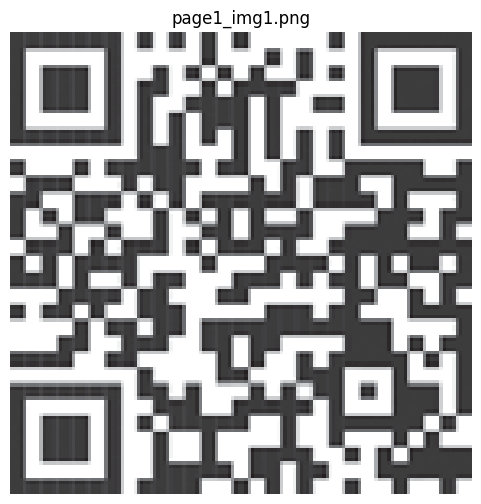

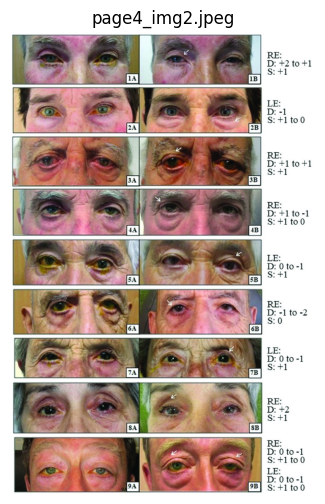

✅ 抽出された画像の総数: 2
✅ 保存フォルダ: /content/abalo_figures


In [4]:
import fitz  # PyMuPDF
import os
from PIL import Image
import matplotlib.pyplot as plt

# ==============================
# 1. 対象PDF
# ==============================
pdf_path = "/content/drive/MyDrive/Paperpile/All Papers/A/Abalo-Lojo et al. 2023 - Improvement of Prostaglandin-Associated Periorbitopathy after Discontinuing Treatment.pdf"

# ==============================
# 2. 出力フォルダ
# ==============================
out_dir = "/content/abalo_figures"
os.makedirs(out_dir, exist_ok=True)

# ==============================
# 3. PDFオープン
# ==============================
doc = fitz.open(pdf_path)

img_count = 0
saved_files = []

# ==============================
# 4. 全ページ走査して画像抽出
# ==============================
for page_index in range(doc.page_count):
    page = doc[page_index]
    image_list = page.get_images(full=True)

    if not image_list:
        continue

    for img_index, img in enumerate(image_list):
        xref = img[0]
        base_image = doc.extract_image(xref)
        image_bytes = base_image["image"]
        image_ext = base_image["ext"]

        img_count += 1
        filename = f"page{page_index+1}_img{img_count}.{image_ext}"
        filepath = os.path.join(out_dir, filename)

        with open(filepath, "wb") as f:
            f.write(image_bytes)

        saved_files.append(filepath)

        # --- その場で表示 ---
        img_pil = Image.open(filepath)
        plt.figure(figsize=(6,6))
        plt.imshow(img_pil)
        plt.axis("off")
        plt.title(filename)
        plt.show()

# ==============================
# 5. 結果サマリ
# ==============================
print("✅ 抽出された画像の総数:", img_count)
print("✅ 保存フォルダ:", out_dir)


#**Pypdfを用いた図の抽出**

In [8]:
!pip install -q pypdf pillow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 329.5/329.5 kB 9.0 MB/s eta 0:00:00


In [9]:
import os
from pypdf import PdfReader
from PIL import Image
import io

pdf_path = "/content/drive/MyDrive/Paperpile/All Papers/A/Abalo-Lojo et al. 2023 - Improvement of Prostaglandin-Associated Periorbitopathy after Discontinuing Treatment.pdf"
out_dir = "/content/pdf_images_pypdf"
os.makedirs(out_dir, exist_ok=True)

reader = PdfReader(pdf_path)

img_count = 0

for page_index, page in enumerate(reader.pages):
    resources = page.get("/Resources")
    if resources is None:
        continue

    xobjects = resources.get("/XObject")
    if xobjects is None:
        continue

    for name, xobj in xobjects.items():
        xobj = xobj.get_object()
        subtype = xobj.get("/Subtype")

        # 画像XObjectだけ対象
        if subtype != "/Image":
            continue

        img_count += 1
        width = xobj.get("/Width")
        height = xobj.get("/Height")
        color_space = xobj.get("/ColorSpace")
        bits = xobj.get("/BitsPerComponent")
        fltr = xobj.get("/Filter")

        data = xobj.get_data()  # フィルタ適用後のバイト列

        # 拡張子推定
        if fltr == "/DCTDecode":
            ext = "jpg"
        elif fltr == "/JPXDecode":
            ext = "jp2"
        elif fltr in ("/FlateDecode", None):
            ext = "png"
        else:
            ext = "bin"

        out_path = os.path.join(out_dir, f"page{page_index+1}_img{img_count}.{ext}")

        # JPEG/JP2ならそのまま書き出し
        if ext in ("jpg", "jp2"):
            with open(out_path, "wb") as f:
                f.write(data)
        else:
            # FlateDecodeなど → Pillowで画像化を試みる
            try:
                img = Image.frombytes(
                    "RGB" if color_space in ("/DeviceRGB", "DeviceRGB") else "L",
                    (width, height),
                    data
                )
                img.save(out_path)
            except Exception as e:
                # うまく復元できない場合はダンプだけ残す
                bin_path = out_path.replace("." + ext, ".bin")
                with open(bin_path, "wb") as f:
                    f.write(data)
                print(f"⚠ 画像復元失敗, 生データ保存: {bin_path} (理由: {e})")

        print(f"保存: {out_path}")

print("✅ 抽出完了, 総画像数:", img_count)
print("保存先:", out_dir)


保存: /content/pdf_images_pypdf/page1_img1.png
保存: /content/pdf_images_pypdf/page4_img2.jpg
✅ 抽出完了, 総画像数: 2
保存先: /content/pdf_images_pypdf
